# 1. Import Required Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans, DBSCAN
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score
import warnings
warnings.filterwarnings('ignore')

## 2. Load the Dataset

In [6]:
df = pd.read_csv('Mall_Customers.csv')

# Display basic information
print("Dataset Shape:", df.shape)
print("\nFirst 5 rows:")
print(df.head())
print("\n\n")
print("\nDataset Info:")
print(df.info())
print("\n\n")
print("\nMissing values:")
print(df.isnull().sum())
print("\n")

Dataset Shape: (200, 5)

First 5 rows:
   CustomerID  Gender  Age  Annual Income (k$)  Spending Score (1-100)
0           1    Male   19                  15                      39
1           2    Male   21                  15                      81
2           3  Female   20                  16                       6
3           4  Female   23                  16                      77
4           5  Female   31                  17                      40




Dataset Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   CustomerID              200 non-null    int64 
 1   Gender                  200 non-null    object
 2   Age                     200 non-null    int64 
 3   Annual Income (k$)      200 non-null    int64 
 4   Spending Score (1-100)  200 non-null    int64 
dtypes: int64(4), object(1)
memory usage: 7.9+ KB

## 3. Data Exploration and initial analysis

In [7]:
print("\nStatistical Summary:")
print(df.describe())


Statistical Summary:
       CustomerID         Age  Annual Income (k$)  Spending Score (1-100)
count  200.000000  200.000000          200.000000              200.000000
mean   100.500000   38.850000           60.560000               50.200000
std     57.879185   13.969007           26.264721               25.823522
min      1.000000   18.000000           15.000000                1.000000
25%     50.750000   28.750000           41.500000               34.750000
50%    100.500000   36.000000           61.500000               50.000000
75%    150.250000   49.000000           78.000000               73.000000
max    200.000000   70.000000          137.000000               99.000000


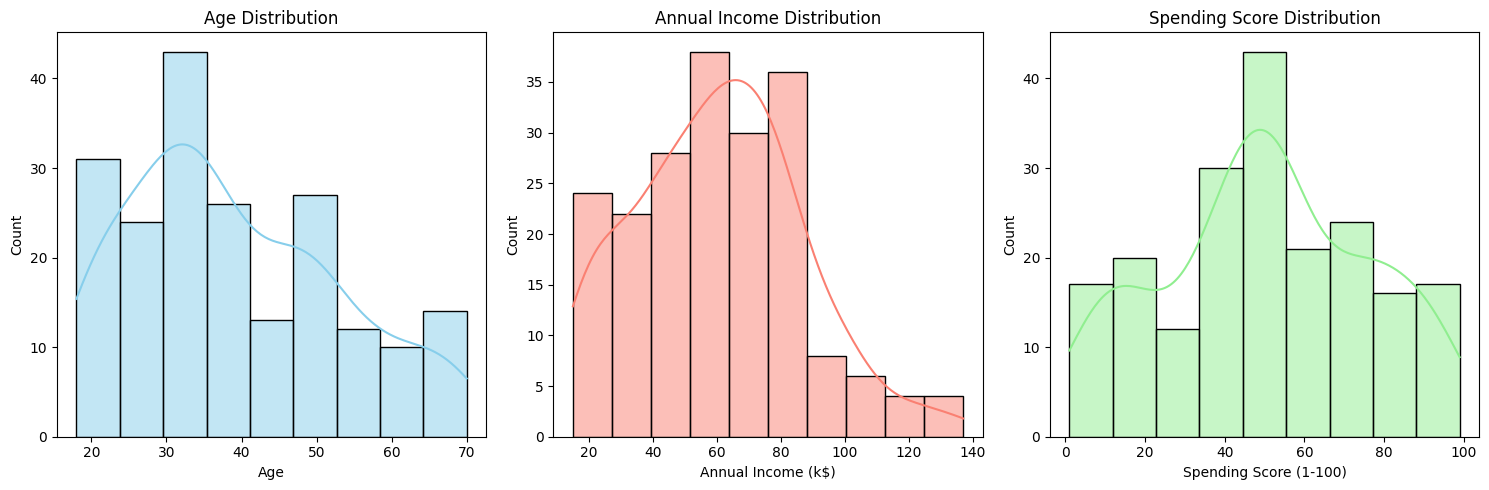

In [10]:
plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
sns.histplot(df['Age'], kde=True, color='skyblue')
plt.title('Age Distribution')

plt.subplot(1, 3, 2)
sns.histplot(df['Annual Income (k$)'], kde=True, color='salmon')
plt.title('Annual Income Distribution')

plt.subplot(1, 3, 3)
sns.histplot(df['Spending Score (1-100)'], kde=True, color='lightgreen')
plt.title('Spending Score Distribution')

plt.tight_layout()
plt.show()

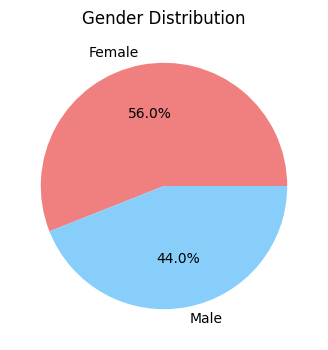

In [13]:
# Gender Distrubtion

plt.figure(figsize=(6,4))
gender_counts = df['Gender'].value_counts()
plt.pie(gender_counts, labels=gender_counts.index, autopct='%1.1f%%', colors=['lightcoral', 'lightskyblue'])
plt.title('Gender Distribution')
plt.show()

## 4. Perpare Data for Clustering

In [17]:
X = df[['Annual Income (k$)', 'Spending Score (1-100)']]

# Standardize the data 
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("Data prepared for clustering:")
print("Features shape:", X.shape)

Data prepared for clustering:
Features shape: (200, 2)


## 5. Determine optimal number of clusters using Elbow Method

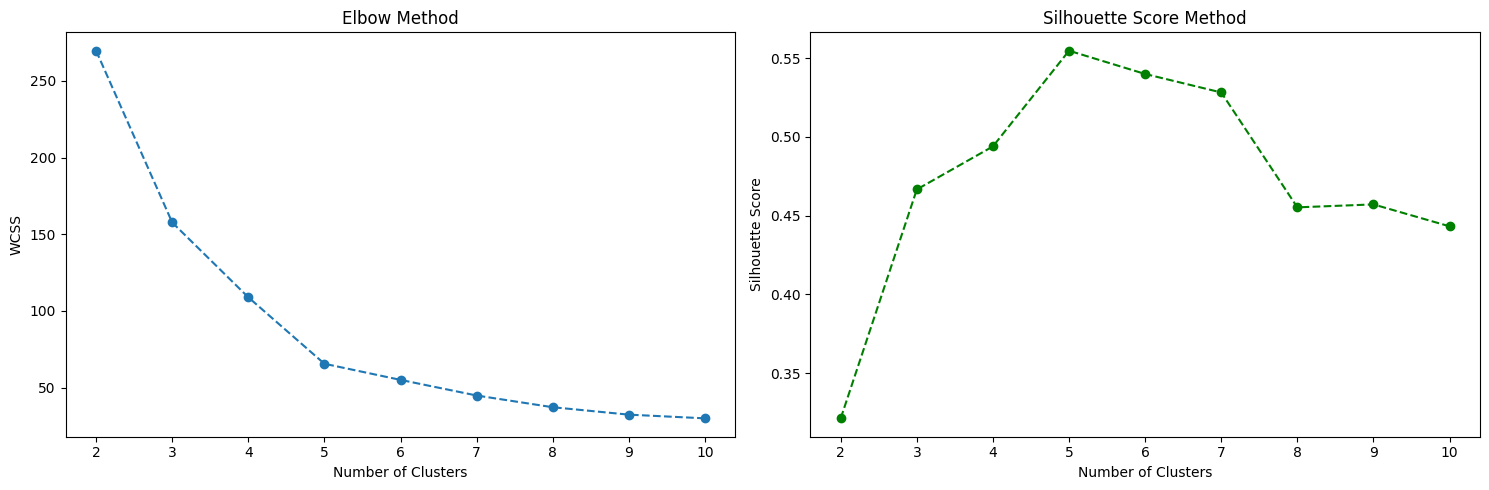

In [18]:
wcss = []  # Within-Cluster Sum of Square
silhouette_scores = []

for i in range(2, 11):
    kmeans = KMeans(n_clusters=i, init='k-means++', random_state=42, n_init=10)
    kmeans.fit(X_scaled)
    wcss.append(kmeans.inertia_)
    
    # Calculate silhouette score
    silhouette_avg = silhouette_score(X_scaled, kmeans.labels_)
    silhouette_scores.append(silhouette_avg)

# Plot the Elbow Method graph
plt.figure(figsize=(15, 5))

plt.subplot(1, 2, 1)
plt.plot(range(2, 11), wcss, marker='o', linestyle='--')
plt.xlabel('Number of Clusters')
plt.ylabel('WCSS')
plt.title('Elbow Method')

plt.subplot(1, 2, 2)
plt.plot(range(2, 11), silhouette_scores, marker='o', linestyle='--', color='green')
plt.xlabel('Number of Clusters')
plt.ylabel('Silhouette Score')
plt.title('Silhouette Score Method')

plt.tight_layout()
plt.show()

## 6. Apply K-Means Clustering with 5 clusters

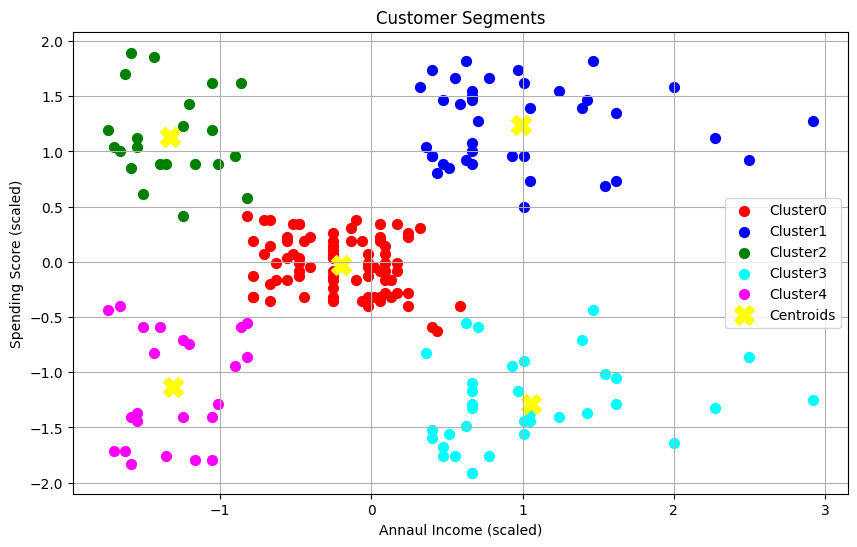

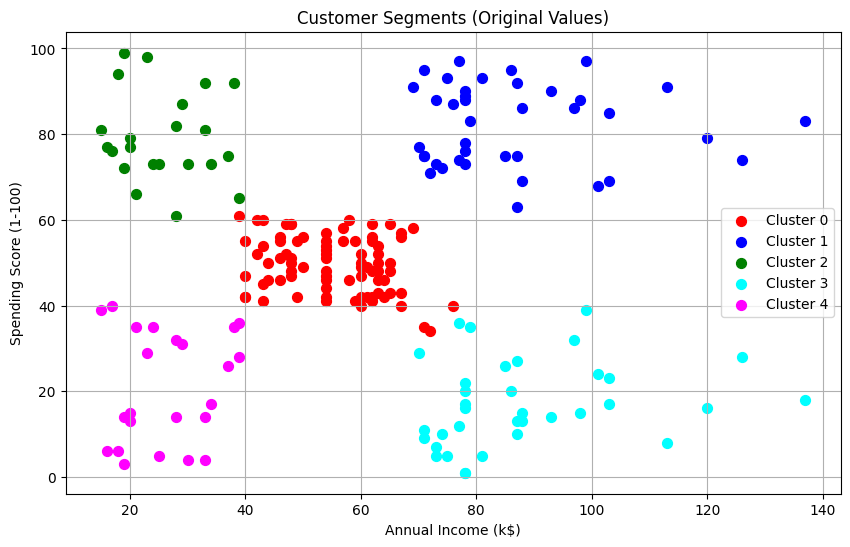

In [21]:
kmeans = KMeans(n_clusters=5, init='k-means++', random_state=42, n_init=10)
clusters = kmeans.fit_predict(X_scaled)

#Add cluster labels to datframe 
df['Cluster'] = clusters

#Visualize the dataframe
plt.figure(figsize=(10,6))
colors = ['red', 'blue', 'green' , 'cyan', 'magenta']

for i in range(5):
    plt.scatter(X_scaled[clusters == i, 0], X_scaled[clusters == i, 1],
                s=50 , c=colors[i], label=f'Cluster{i}')

plt.scatter(kmeans.cluster_centers_[:, 0], kmeans.cluster_centers_[:, 1],
            s=200, c='yellow', label='Centroids', marker='X')
plt.title('Customer Segments')
plt.xlabel('Annaul Income (scaled)')
plt.ylabel('Spending Score (scaled)')
plt.legend()
plt.grid(True)
plt.show()


#visualize clusters with original values 
plt.figure(figsize=(10,6))
for i in range(5):
    plt.scatter(df[df['Cluster'] == i]['Annual Income (k$)'], 
                df[df['Cluster'] == i]['Spending Score (1-100)'], 
                s=50, c=colors[i], label=f'Cluster {i}')

plt.title('Customer Segments (Original Values)')
plt.xlabel('Annual Income (k$)')
plt.ylabel('Spending Score (1-100)')
plt.legend()
plt.grid(True)
plt.show()

## 7. Cluster analysis

Cluster Analysis:
           Age  Annual Income (k$)  Spending Score (1-100)  Count
Cluster                                                          
0        42.72               55.30                   49.52     81
1        32.69               86.54                   82.13     39
2        25.27               25.73                   79.36     22
3        41.11               88.20                   17.11     35
4        45.22               26.30                   20.91     23


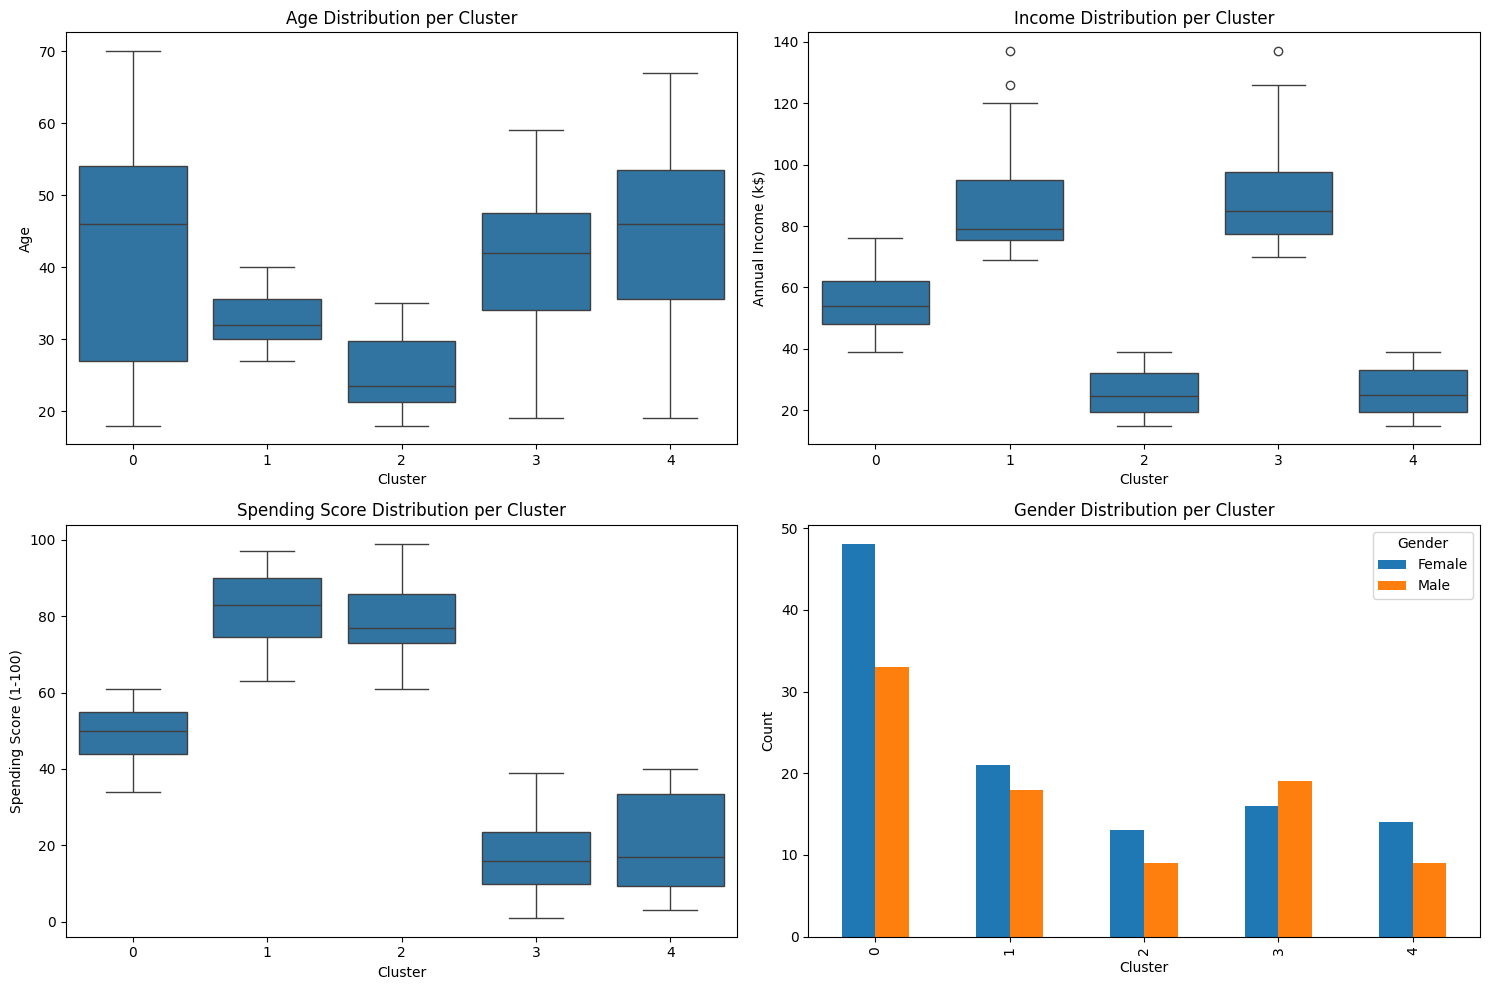

In [24]:
# 7. Cluster analysis 
cluster_analysis = df.groupby('Cluster').agg({
    'Age': 'mean',
    'Annual Income (k$)': 'mean',  
    'Spending Score (1-100)': 'mean',
    'CustomerID': 'count'
}).rename(columns={'CustomerID': 'Count'})

print("Cluster Analysis:")
print(cluster_analysis.round(2))


# Visualize cluster characteristics
fig, axes = plt.subplots(2, 2, figsize=(15, 10))

sns.boxplot(x='Cluster', y='Age', data=df, ax=axes[0, 0])
axes[0, 0].set_title('Age Distribution per Cluster')

sns.boxplot(x='Cluster', y='Annual Income (k$)', data=df, ax=axes[0, 1])  
axes[0, 1].set_title('Income Distribution per Cluster')

sns.boxplot(x='Cluster', y='Spending Score (1-100)', data=df, ax=axes[1, 0])
axes[1, 0].set_title('Spending Score Distribution per Cluster')

cluster_gender = pd.crosstab(df['Cluster'], df['Gender'])
cluster_gender.plot(kind='bar', ax=axes[1, 1])
axes[1, 1].set_title('Gender Distribution per Cluster')
axes[1, 1].set_ylabel('Count')

plt.tight_layout()
plt.show()

## 8. (BONUS) Try DBSCAN clustering

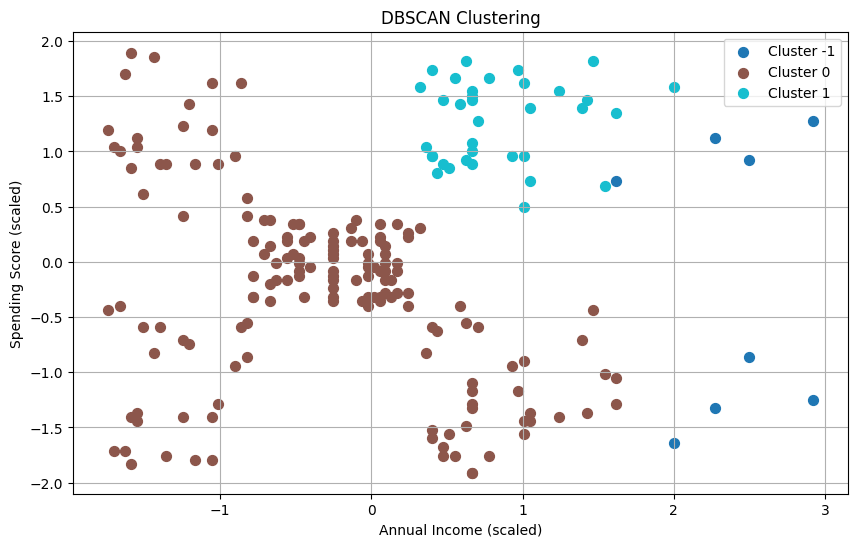

K-Means found 5 clusters
DBSCAN found 3 clusters


In [26]:
dbscan = DBSCAN(eps=0.5, min_samples=5)
dbscan_clusters = dbscan.fit_predict(X_scaled)

df['DBSCAN_Cluster'] = dbscan_clusters

plt.figure(figsize=(10,6))
unique_clusters = np.unique(dbscan_clusters)
colors = plt.cm.tab10(np.linspace(0, 1, len(unique_clusters)))

for i, cluster in enumerate(unique_clusters):
    plt.scatter(X_scaled[dbscan_clusters == cluster, 0],
                X_scaled[dbscan_clusters == cluster, 1], 
                s=50, color=colors[i], label=f'Cluster {cluster}')

plt.title('DBSCAN Clustering')
plt.xlabel('Annual Income (scaled)')
plt.ylabel('Spending Score (scaled)')
plt.legend()
plt.grid(True)
plt.show()
                
                
# Compare methods
print(f"K-Means found {len(np.unique(clusters))} clusters")
print(f"DBSCAN found {len(np.unique(dbscan_clusters))} clusters")


## 9. Create customer profiles  

In [28]:
cluster_profiles = []
for i in range(5):
    cluster_data = df[df['Cluster'] == i]
    profile = {
        'Cluster': i,
        'Size': len(cluster_data),
        'Avg_Age': cluster_data['Age'].mean(),
        'Avg_Income': cluster_data['Annual Income (k$)'].mean(),
        'Avg_Spending': cluster_data['Spending Score (1-100)'].mean(),
        'Gender_Ratio': f"{len(cluster_data[cluster_data['Gender'] == 'Male'])/len(cluster_data)*100:.1f}% Male"
    }
    cluster_profiles.append(profile)

profiles_df = pd.DataFrame(cluster_profiles)
print("\nCustomer Profiles per Cluster:")
print(profiles_df.round(2))


Customer Profiles per Cluster:
   Cluster  Size  Avg_Age  Avg_Income  Avg_Spending Gender_Ratio
0        0    81    42.72       55.30         49.52   40.7% Male
1        1    39    32.69       86.54         82.13   46.2% Male
2        2    22    25.27       25.73         79.36   40.9% Male
3        3    35    41.11       88.20         17.11   54.3% Male
4        4    23    45.22       26.30         20.91   39.1% Male


## 10. Interpretation and recommendations

In [29]:
print("="*60)
print("CLUSTER INTERPRETATION AND RECOMMENDATIONS")
print("="*60)

interpretations = {
    0: "High Income, Low Spending - Target with premium products",
    1: "Medium Income, Medium Spending - Focus on volume sales",
    2: "High Income, High Spending - Ideal customers, offer VIP treatment",
    3: "Low Income, High Spending - Offer value deals and discounts",
    4: "Low Income, Low Spending - Attract with deep discounts"
}

for i in range(5):
    print(f"\nCluster {i}: {interpretations[i]}")
    print(f"   - Average Age: {profiles_df.loc[i, 'Avg_Age']:.1f} years")
    print(f"   - Average Income: ${profiles_df.loc[i, 'Avg_Income']:.1f}k")
    print(f"   - Average Spending Score: {profiles_df.loc[i, 'Avg_Spending']:.1f}/100")

print("\nResults saved to 'customer_segmentation_results.csv'")
df.to_csv('customer_segmentation_results.csv', index=False)

CLUSTER INTERPRETATION AND RECOMMENDATIONS

Cluster 0: High Income, Low Spending - Target with premium products
   - Average Age: 42.7 years
   - Average Income: $55.3k
   - Average Spending Score: 49.5/100

Cluster 1: Medium Income, Medium Spending - Focus on volume sales
   - Average Age: 32.7 years
   - Average Income: $86.5k
   - Average Spending Score: 82.1/100

Cluster 2: High Income, High Spending - Ideal customers, offer VIP treatment
   - Average Age: 25.3 years
   - Average Income: $25.7k
   - Average Spending Score: 79.4/100

Cluster 3: Low Income, High Spending - Offer value deals and discounts
   - Average Age: 41.1 years
   - Average Income: $88.2k
   - Average Spending Score: 17.1/100

Cluster 4: Low Income, Low Spending - Attract with deep discounts
   - Average Age: 45.2 years
   - Average Income: $26.3k
   - Average Spending Score: 20.9/100

Results saved to 'customer_segmentation_results.csv'


# Thank You